# Tình huống điển hình: CVSS nói thấp, thực tế nói cao

Notebook này tìm các tình huống cụ thể cho thấy khác biệt giữa quy tắc CSA (vá trong 48 giờ mọi lỗ hổng CVSS từ 8,0) và công thức

**S = AC × CVSS × [KEV + (1 - KEV) × EPSS^0,3] × 10** (tạm coi AC = 1).

Để tránh chọn ví dụ có lợi, mọi tình huống được chọn theo **tiêu chí cố định đặt trước**, và báo cáo cả số trường hợp không đạt:

- **Phần A. Công thức bắt trước, quy tắc CSA bỏ qua:** lỗ hổng vào KEV từ 01/04/2023, có CVSS dưới 8,0 (quy tắc CSA không bao giờ ưu tiên), và có S từ 50 trở lên 30 ngày trước khi vào KEV.
- **Phần B. Lịch sử điểm theo tháng** của ba tình huống chọn theo quy tắc: CVSS thấp nhất, báo trước lâu nhất, công bố và vào KEV gần nhau nhất.
- **Phần C. Quy tắc CSA vá thừa, công thức hạ ưu tiên:** lỗ hổng CVSS từ 9,0 chưa có trong KEV tại ngày 30/06/2025.
- **Phần D. Trường hợp công thức không bắt được**, gồm ví dụ CVE-2025-13956 của CrowdSec.

**Cần chạy trước:** `so_sanh_truoc_khi_vao_kev.ipynb` (dùng tệp `ket_qua_truoc_kev/chi_tiet_tung_lo_hong.csv`). Kết quả lưu trong thư mục `ket_qua_tinh_huong`.

## 1. Cấu hình và hàm dùng chung

In [1]:
import os, io, json, gzip, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

DATA_DIR, OUT_DIR = "du_lieu_nvd", "ket_qua_tinh_huong"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
KEV_URL = "https://raw.githubusercontent.com/cisagov/kev-data/develop/known_exploited_vulnerabilities.json"
NVD_FEED = "https://nvd.nist.gov/feeds/json/cve/2.0/nvdcve-2.0-{y}.json.gz"
EPSS_API = "https://api.first.org/data/v1/epss?cve={cves}&date={d}"
EPSS_FILE = "https://epss.empiricalsecurity.com/epss_scores-{d}.csv.gz"
UA = {"User-Agent": "Nhom14-course-research"}
SO_MU, NGUONG_S = 0.3, 50
# Thang EPSS doi mo hinh: v2 (04/02/2022), v3 (07/03/2023), v4 (17/03/2025)
THANG_DOI_MO_HINH = {"2022-02", "2023-03", "2025-03"}
# Ty le lo hong chua co KEV dat tu muc S tro len, ngay 30/06/2025 (tu notebook kiem chung cong thuc S)
THAM_CHIEU = {50: (6868, 209623), 70: (2803, 209623)}
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})

def tai(url, path):
    if os.path.exists(path): return open(path, "rb").read()
    data = urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=300).read()
    open(path, "wb").write(data); return data
def so(x): return f"{int(round(x)):,}".replace(",", ".")
def pct(v, k=2): return f"{v:.{k}f}".replace(".", ",")
def ty_le(a, b, k=2): return f"{so(a)} / {so(b)} = {pct(100 * a / b, k)}%" if b else ""
def diem_S(cvss, epss, kev=0): return cvss * (kev + (1 - kev) * np.power(epss, SO_MU)) * 10
def ngay_vn(t): return pd.Timestamp(t).strftime("%d/%m/%Y")

CACHE = os.path.join(DATA_DIR, "epss_api_tinh_huong.json")
cache = json.load(open(CACHE)) if os.path.exists(CACHE) else {}
def goi_api(ngay, nhom):
    url = EPSS_API.format(cves=",".join(nhom), d=ngay)
    for lan in range(4):
        try:
            js = json.loads(urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=60).read())
            return {d["cve"].upper(): float(d["epss"]) for d in js.get("data", [])} or None
        except urllib.error.HTTPError as e:
            if e.code == 422: return None
            time.sleep(5 * (lan + 1))
        except Exception:
            time.sleep(5 * (lan + 1))
    return None
def doc_tep(ngay):
    raw = urllib.request.urlopen(urllib.request.Request(EPSS_FILE.format(d=ngay), headers=UA), timeout=300).read()
    e = pd.read_csv(io.StringIO(gzip.decompress(raw).decode()), comment="#")
    return dict(zip(e["cve"].str.upper(), e["epss"].astype(float)))
def lay_epss(ngay, cves):
    can = [c for c in cves if f"{ngay}|{c}" not in cache]
    if can:
        tim = goi_api(ngay, can); time.sleep(0.3)
        if tim is None:
            try: tim = doc_tep(ngay)
            except Exception: tim = {}
        for c in can: cache[f"{ngay}|{c}"] = tim.get(c)
    return {c: cache.get(f"{ngay}|{c}") for c in cves}
BANG, SO_LIEU = {}, {}

## 2. Dữ liệu

In [2]:
kev = pd.DataFrame(json.loads(tai(KEV_URL, os.path.join(DATA_DIR, "kev.json")))["vulnerabilities"])
kev["cveID"] = kev["cveID"].str.upper()
ct = pd.read_csv("ket_qua_truoc_kev/chi_tiet_tung_lo_hong.csv", parse_dates=["ngay_kev", "ngay_cong_bo"])
ct = ct.merge(kev[["cveID", "knownRansomwareCampaignUse"]], left_on="cve", right_on="cveID", how="left")
thap = ct[ct["cvss"] < 8.0]
print(f"Lỗ hổng vào KEV từ 01/04/2023: {so(len(ct))}, trong đó CVSS dưới 8,0: {so(len(thap))}")

Lỗ hổng vào KEV từ 01/04/2023: 836, trong đó CVSS dưới 8,0: 328


## 3. Phần A. Công thức bắt trước, quy tắc CSA bỏ qua

Tiêu chí: CVSS dưới 8,0 và S từ 50 trở lên 30 ngày trước khi vào KEV. Ngày 30/06/2025, chỉ 3,28% lỗ hổng chưa có trong KEV đạt S từ 50, nên các lỗ hổng này đã nằm trong nhóm ưu tiên cao của công thức một tháng trước khi CISA xác nhận bị khai thác.

In [3]:
co30 = thap[thap["S_30"].notna()]
A = co30[co30["S_30"] >= NGUONG_S].sort_values("S_30", ascending=False).copy()
bA = pd.DataFrame([
    ["Lỗ hổng KEV có CVSS dưới 8,0 (quy tắc CSA không ưu tiên lỗ hổng nào)", so(len(thap)), ""],
    ["Có điểm EPSS 30 ngày trước khi vào KEV", ty_le(len(co30), len(thap)), ""],
    ["S từ 50 trở lên 30 ngày trước khi vào KEV", ty_le(len(A), len(co30)),
     f"Công thức bắt trước; tính trên cả lỗ hổng CVSS dưới 8,0: {ty_le(len(A), len(thap))}"],
    ["S từ 70 trở lên 30 ngày trước khi vào KEV", ty_le(int((co30["S_30"] >= 70).sum()), len(co30)),
     f"Ngưỡng vá khẩn cấp; tính trên cả lỗ hổng CVSS dưới 8,0: {ty_le(int((co30['S_30'] >= 70).sum()), len(thap))}"],
    ["S dưới 30, 30 ngày trước khi vào KEV", ty_le(int((co30["S_30"] < 30).sum()), len(co30)), "Công thức không bắt trước"],
], columns=["Hạng mục", "Số lượng", "Ghi chú"])
BANG["A1 Tong quan"] = bA; display(bA)
dsA = pd.DataFrame({"Mã CVE": A["cve"], "Sản phẩm": A["vendorProject"] + " " + A["product"], "CVSS": A["cvss"].map(lambda v: pct(v, 1)),
                    "Ngày công bố": A["ngay_cong_bo"].map(ngay_vn), "Ngày vào KEV": A["ngay_kev"].map(ngay_vn),
                    "EPSS 30 ngày trước": A["epss_30"].map(lambda v: pct(v, 4)), "S 30 ngày trước": A["S_30"].map(lambda v: pct(v, 1)),
                    "S khi vào KEV": A["S_kev"].map(lambda v: pct(v, 1)),
                    "Mã độc tống tiền": A["knownRansomwareCampaignUse"].map({"Known": "Có", "Unknown": "Chưa rõ"})})
BANG["A2 Danh sach"] = dsA; display(dsA)
SO_LIEU["A"] = dict(thap=len(thap), co30=len(co30), dat50=len(A), dat70=int((co30["S_30"] >= 70).sum()),
                    duoi30=int((co30["S_30"] < 30).sum()))

,Hạng mục,Số lượng,Ghi chú
0,"Lỗ hổng KEV có CVSS dưới 8,0 (quy tắc CSA khôn...",328,
1,Có điểm EPSS 30 ngày trước khi vào KEV,"156 / 328 = 47,56%",
2,S từ 50 trở lên 30 ngày trước khi vào KEV,"24 / 156 = 15,38%",Công thức bắt trước; tính trên cả lỗ hổng CVSS...
3,S từ 70 trở lên 30 ngày trước khi vào KEV,"14 / 156 = 8,97%",Ngưỡng vá khẩn cấp; tính trên cả lỗ hổng CVSS ...
4,"S dưới 30, 30 ngày trước khi vào KEV","119 / 156 = 76,28%",Công thức không bắt trước


,Mã CVE,Sản phẩm,CVSS,Ngày công bố,Ngày vào KEV,EPSS 30 ngày trước,S 30 ngày trước,S khi vào KEV,Mã độc tống tiền
806,CVE-2016-6415,"Cisco IOS, IOS XR, and IOS XE","7,5",19/09/2016,19/05/2023,"0,9727","74,4","75,0",Chưa rõ
793,CVE-2016-9079,"Mozilla Firefox, Firefox ESR, and Thunderbird","7,5",11/06/2018,22/06/2023,"0,9719","74,4","75,0",Chưa rõ
626,CVE-2020-17519,Apache Flink,"7,5",05/01/2021,23/05/2024,"0,9708","74,3","75,0",Chưa rõ
529,CVE-2021-41277,Metabase Metabase,"7,5",17/11/2021,12/11/2024,"0,9515","73,9","75,0",Chưa rõ
303,CVE-2021-43798,Grafana Labs Grafana,"7,5",07/12/2021,09/10/2025,"0,9434","73,7","75,0",Chưa rõ
362,CVE-2019-5418,Rails Ruby on Rails,"7,5",27/03/2019,07/07/2025,"0,9423","73,7","75,0",Chưa rõ
345,CVE-2020-25078,D-Link DCS-2530L and DCS-2670L Devices,"7,5",02/09/2020,05/08/2025,"0,9403","73,6","75,0",Chưa rõ
305,CVE-2021-22555,Linux Kernel,"7,8",07/07/2021,06/10/2025,"0,8242","73,6","78,0",Chưa rõ
621,CVE-2017-3506,Oracle WebLogic Server,"7,4",24/04/2017,03/06/2024,"0,9688","73,3","74,0",Chưa rõ
361,CVE-2019-9621,Synacor Zimbra Collaboration Suite (ZCS),"7,5",30/04/2019,07/07/2025,"0,9181","73,1","75,0",Chưa rõ


## 4. Phần B. Lịch sử điểm theo tháng

Lấy điểm EPSS vào ngày cuối mỗi tháng, từ tháng công bố (sớm nhất 05/2021, khi có dữ liệu EPSS lịch sử) đến 3 tháng sau khi vào KEV. Tính điểm S theo từng tháng, kể cả bước nhảy khi lỗ hổng vào KEV (S = CVSS × 10). Đồng thời tìm **tháng đầu tiên S đạt từ 50**, để biết công thức báo trước bao lâu.

Thời gian báo trước tính theo hai cách: từ **lần đầu** S đạt 50, và từ đầu **chuỗi tháng liên tục** có S từ 50 cho tới khi vào KEV (sát hơn với việc tổ chức thực sự giữ lỗ hổng trong nhóm ưu tiên). Lần đầu đạt 50 được phân loại: trùng tháng EPSS đổi mô hình (02/2022, 03/2023, 03/2025), tháng đầu có điểm, hoặc tăng dần theo EPSS.

In [4]:
def cuoi_thang(t0, t1):
    return [d.strftime("%Y-%m-%d") for d in pd.date_range(t0, t1, freq="ME")]
lich = []
for _, r in A.iterrows():
    t0 = max(r["ngay_cong_bo"], pd.Timestamp("2021-05-01")); t1 = min(r["ngay_kev"] + pd.DateOffset(months=3), pd.Timestamp("2026-09-30"))
    for d in cuoi_thang(t0, t1): lich.append((d, r["cve"]))
lich = pd.DataFrame(lich, columns=["ngay", "cve"])
for d, g in lich.groupby("ngay"): lay_epss(d, list(g["cve"]))
json.dump(cache, open(CACHE, "w"))
lich["epss"] = [cache.get(f"{d}|{c}") for d, c in zip(lich["ngay"], lich["cve"])]
lich = lich.merge(A[["cve", "cvss", "ngay_kev", "ngay_cong_bo"]], on="cve")
lich["ngay"] = pd.to_datetime(lich["ngay"]); lich["kev"] = (lich["ngay"] >= lich["ngay_kev"]).astype(int)
lich["S"] = [diem_S(c, e, k) if e is not None and not pd.isna(e) else np.nan for c, e, k in zip(lich["cvss"], lich["epss"], lich["kev"])]

bao_truoc = []
for c, g in lich.groupby("cve"):
    g = g[g["kev"] == 0].dropna(subset=["S"])
    g = lich[(lich["cve"] == c) & (lich["kev"] == 0)].sort_values("ngay")
    dat = g[g["S"] >= NGUONG_S]
    dau = dat["ngay"].min() if len(dat) else pd.NaT
    kd = A.loc[A["cve"] == c, "ngay_kev"].iloc[0]
    # Bao truoc lien tuc: tu dau chuoi thang lien tuc co S tu 50 ket thuc o thang cuoi truoc khi vao KEV
    co = (g["S"] >= NGUONG_S).values; j = len(co)
    while j > 0 and co[j - 1]: j -= 1
    lien = g["ngay"].iloc[j] if j < len(co) else pd.NaT
    # Phan loai lan dau dat: trung thang EPSS doi mo hinh, thang dau co diem, hay tang dan theo EPSS
    truoc = g[g["ngay"] < dau]["S"] if pd.notna(dau) else pd.Series(dtype=float)
    if pd.isna(dau): loai = ""
    elif dau.strftime("%Y-%m") in THANG_DOI_MO_HINH: loai = "Trùng tháng EPSS đổi mô hình"
    elif truoc.dropna().empty: loai = "Tháng đầu có điểm"
    else: loai = "Tăng theo EPSS"
    bao_truoc.append(dict(cve=c, thang_dau_dat=dau, ngay_kev=kd, so_thang=(kd - dau).days / 30.44 if pd.notna(dau) else np.nan,
                          bat_dau_lien_tuc=lien, so_thang_lien_tuc=(kd - lien).days / 30.44 if pd.notna(lien) else np.nan,
                          thang_duoi_nguong=int((g[g["ngay"] >= dau]["S"] < NGUONG_S).sum()) if pd.notna(dau) else 0, loai=loai))
bt = pd.DataFrame(bao_truoc).merge(A[["cve", "vendorProject", "product", "cvss", "ngay_cong_bo"]], on="cve").sort_values("so_thang", ascending=False)
bB = pd.DataFrame({"Mã CVE": bt["cve"], "Sản phẩm": bt["vendorProject"] + " " + bt["product"], "CVSS": bt["cvss"].map(lambda v: pct(v, 1)),
                   "Tháng đầu tiên S từ 50": bt["thang_dau_dat"].map(lambda t: t.strftime("%m/%Y") if pd.notna(t) else "Không đạt"),
                   "Ngày vào KEV": bt["ngay_kev"].map(ngay_vn),
                   "Báo trước (tháng)": bt["so_thang"].map(lambda v: pct(v, 0) if pd.notna(v) else ""),
                   "Ngày gần nhất trở lại S từ 50": bt["bat_dau_lien_tuc"].map(lambda t: ngay_vn(t) if pd.notna(t) else ""),
                   "Báo trước liên tục (tháng)": bt["so_thang_lien_tuc"].map(lambda v: pct(v, 0) if pd.notna(v) else ""),
                   "Số tháng rơi dưới 50 sau lần đầu": bt["thang_duoi_nguong"], "Lần đầu đạt 50": bt["loai"]})
BANG["B1 Bao truoc"] = bB; display(bB)
SO_LIEU["B"] = dict(trung_vi_thang=float(bt["so_thang"].median()), it_nhat_12=int((bt["so_thang"] >= 12).sum()), n=len(bt),
                    trung_vi_lien_tuc=float(bt["so_thang_lien_tuc"].median()), it_nhat_12_lien_tuc=int((bt["so_thang_lien_tuc"] >= 12).sum()),
                    phan_loai=bt["loai"].value_counts().to_dict())
print(f"Trung vị thời gian báo trước: {pct(bt['so_thang'].median(), 1)} tháng; "
      f"báo trước từ 12 tháng trở lên: {ty_le(int((bt['so_thang'] >= 12).sum()), len(bt))}")
print(f"Tính liên tục: trung vị {pct(bt['so_thang_lien_tuc'].median(), 1)} tháng; "
      f"từ 12 tháng trở lên: {ty_le(int((bt['so_thang_lien_tuc'] >= 12).sum()), len(bt))}")
print("Lần đầu đạt 50:", "; ".join(f"{k}: {v}" for k, v in bt["loai"].value_counts().items()))

,Mã CVE,Sản phẩm,CVSS,Tháng đầu tiên S từ 50,Ngày vào KEV,Báo trước (tháng),Ngày gần nhất trở lại S từ 50,Báo trước liên tục (tháng),Số tháng rơi dưới 50 sau lần đầu,Lần đầu đạt 50
0,CVE-2015-5477,ISC BIND,"7,5",02/2022,08/10/2026,55,28/02/2022,55,0,Trùng tháng EPSS đổi mô hình
9,CVE-2020-9715,Adobe Acrobat,"7,8",01/2022,13/04/2026,50,31/05/2023,34,15,Tăng theo EPSS
6,CVE-2019-9621,Synacor Zimbra Collaboration Suite (ZCS),"7,5",05/2021,07/07/2025,49,31/05/2021,49,0,Tháng đầu có điểm
5,CVE-2019-5418,Rails Ruby on Rails,"7,5",05/2021,07/07/2025,49,31/05/2021,49,0,Tháng đầu có điểm
12,CVE-2021-22555,Linux Kernel,"7,8",10/2021,06/10/2025,47,31/03/2025,6,37,Tăng theo EPSS
16,CVE-2021-43798,Grafana Labs Grafana,"7,5",12/2021,09/10/2025,45,31/12/2021,45,0,Tháng đầu có điểm
7,CVE-2020-17519,Apache Flink,"7,5",05/2021,23/05/2024,36,31/05/2021,36,0,Tháng đầu có điểm
11,CVE-2021-22054,Omnissa Workspace One UEM,"7,5",03/2023,09/03/2026,35,31/03/2023,35,0,Trùng tháng EPSS đổi mô hình
4,CVE-2018-9276,Paessler PRTG Network Monitor,"7,2",02/2022,04/02/2025,35,28/02/2022,35,0,Trùng tháng EPSS đổi mô hình
8,CVE-2020-25078,D-Link DCS-2530L and DCS-2670L Devices,"7,5",03/2023,05/08/2025,28,31/03/2023,28,0,Trùng tháng EPSS đổi mô hình


Trung vị thời gian báo trước: 19,4 tháng; báo trước từ 12 tháng trở lên: 18 / 24 = 75,00%
Tính liên tục: trung vị 14,3 tháng; từ 12 tháng trở lên: 15 / 24 = 62,50%
Lần đầu đạt 50: Trùng tháng EPSS đổi mô hình: 12; Tăng theo EPSS: 8; Tháng đầu có điểm: 4


### Hình 1. Ba tình huống chọn theo quy tắc

- CVSS thấp nhất trong danh sách phần A.
- Báo trước lâu nhất.
- Thời gian từ khi công bố đến khi vào KEV ngắn nhất.

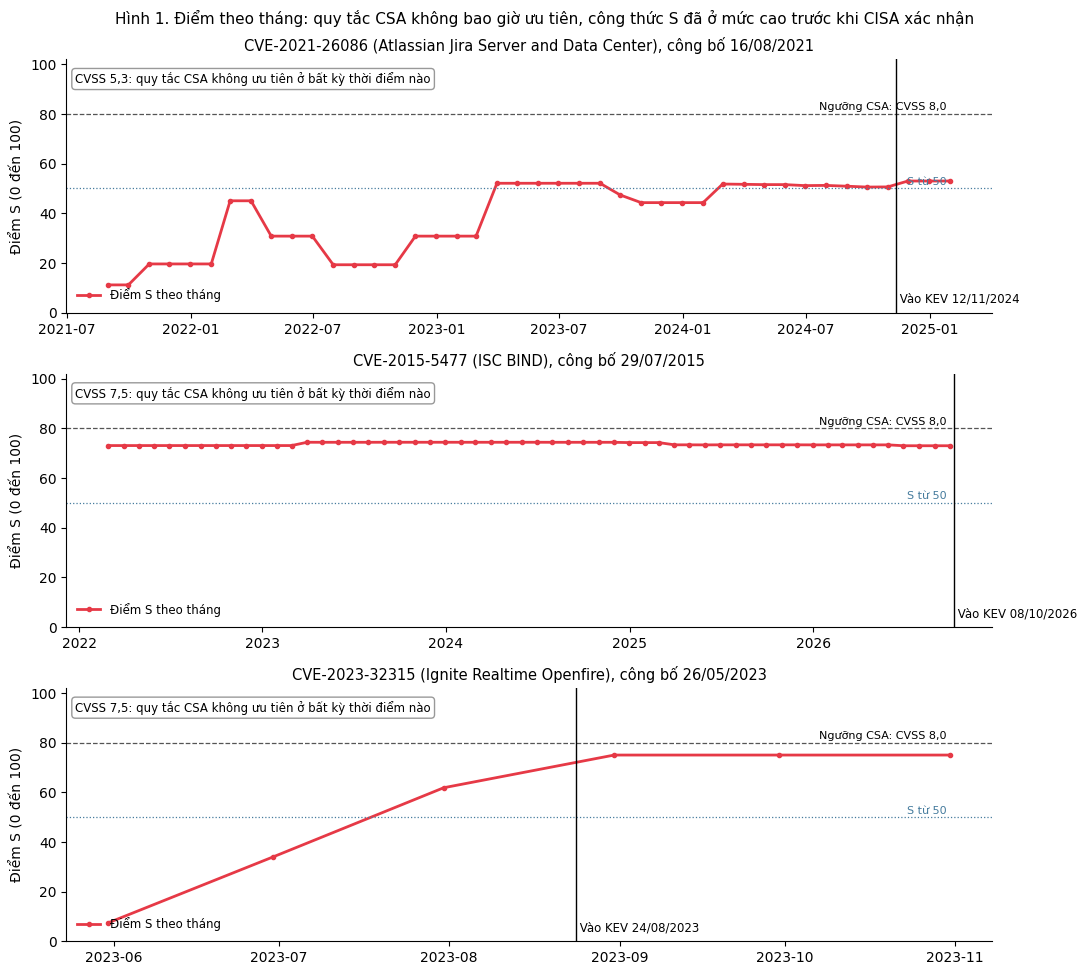

In [5]:
chon = []
chon.append(A.sort_values(["cvss", "S_30"], ascending=[True, False]).iloc[0]["cve"])
chon.append(bt.dropna(subset=["so_thang"]).iloc[0]["cve"])
A["khoang"] = (A["ngay_kev"] - A["ngay_cong_bo"]).dt.days
chon.append(A.sort_values("khoang").iloc[0]["cve"])
chon = list(dict.fromkeys(chon))
SO_LIEU["chon"] = chon
fig, axs = plt.subplots(len(chon), 1, figsize=(11, 3.3 * len(chon)))
for ax, c in zip(np.atleast_1d(axs), chon):
    g = lich[lich["cve"] == c].sort_values("ngay"); r = A[A["cve"] == c].iloc[0]
    ax.plot(g["ngay"], g["S"], color="#e63946", lw=2, marker="o", ms=3, label="Điểm S theo tháng")
    ax.axhline(80, color="#555555", lw=0.9, ls="--"); ax.text(g["ngay"].max(), 81.5, "Ngưỡng CSA: CVSS 8,0 ", fontsize=8, ha="right")
    ax.axhline(NGUONG_S, color="#457b9d", lw=0.9, ls=":"); ax.text(g["ngay"].max(), NGUONG_S + 1.5, "S từ 50 ", fontsize=8, color="#457b9d", ha="right")
    ax.axvline(r["ngay_kev"], color="black", lw=1); ax.text(r["ngay_kev"], 4, " Vào KEV " + ngay_vn(r["ngay_kev"]), fontsize=8.5)
    ax.text(0.01, 0.95, f"CVSS {pct(r['cvss'], 1)}: quy tắc CSA không ưu tiên ở bất kỳ thời điểm nào", transform=ax.transAxes,
            fontsize=8.5, va="top", bbox=dict(facecolor="white", edgecolor="#999999", boxstyle="round,pad=0.3"))
    ax.set_ylim(0, 102); ax.set_ylabel("Điểm S (0 đến 100)")
    ax.set_title(f"{c} ({r['vendorProject']} {r['product']}), công bố {ngay_vn(r['ngay_cong_bo'])}", fontsize=10.5)
    ax.legend(frameon=False, fontsize=8.5, loc="lower left")
fig.suptitle("Hình 1. Điểm theo tháng: quy tắc CSA không bao giờ ưu tiên, công thức S đã ở mức cao trước khi CISA xác nhận", fontsize=11)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh1_lich_su_diem.png"), dpi=170); plt.show()

## 5. Phần C. Quy tắc CSA vá thừa, công thức hạ ưu tiên

Tại ngày 30/06/2025, xét lỗ hổng CVSS từ 9,0 chưa có trong KEV. Quy tắc CSA bắt vá tất cả trong 48 giờ. Công thức chia chúng theo điểm S. Theo dõi 12 tháng sau xem bao nhiêu lỗ hổng thực sự vào KEV.

In [6]:
T = pd.Timestamp("2025-06-30"); H = T + pd.Timedelta(days=365)
rows = []
for y in range(2002, 2026):
    js = json.loads(gzip.decompress(tai(NVD_FEED.format(y=y), os.path.join(DATA_DIR, f"nvdcve-2.0-{y}.json.gz"))))
    for it in js["vulnerabilities"]:
        c = it["cve"]
        if c.get("vulnStatus") == "Rejected": continue
        met = c.get("metrics", {}); v = met.get("cvssMetricV31") or met.get("cvssMetricV30")
        if not v: continue
        p = [m for m in v if m.get("type") == "Primary"] or v
        rows.append((c["id"].upper(), c["published"][:10], p[0]["cvssData"]["baseScore"]))
nvd = pd.DataFrame(rows, columns=["cve", "pub", "cvss"]).drop_duplicates("cve"); nvd["pub"] = pd.to_datetime(nvd["pub"])
kd = dict(zip(kev["cveID"], pd.to_datetime(kev["dateAdded"])))
nvd["kev_d"] = nvd["cve"].map(kd)
raw = gzip.decompress(tai(EPSS_FILE.format(d="2025-06-30"), os.path.join(DATA_DIR, "epss_2025-06-30.csv.gz"))).decode()
ep = pd.read_csv(io.StringIO(raw), comment="#"); em = dict(zip(ep["cve"].str.upper(), ep["epss"]))
x = nvd[(nvd["pub"] <= T) & ~(nvd["kev_d"].notna() & (nvd["kev_d"] <= T)) & (nvd["cvss"] >= 9.0)].copy()
x["epss"] = x["cve"].map(em).fillna(0.0); x["S"] = diem_S(x["cvss"].values, x["epss"].values)
x["y"] = (x["kev_d"].notna() & (x["kev_d"] > T) & (x["kev_d"] <= H)).astype(int)
x["nhom"] = pd.cut(x["S"], [0, 30, 50, 70, 100.001], labels=["S dưới 30", "S từ 30 đến dưới 50", "S từ 50 đến dưới 70", "S từ 70 trở lên"], right=False)
t = x.groupby("nhom", observed=False)["y"].agg(["size", "sum"])
N, P = len(x), int(x["y"].sum())
bC = pd.DataFrame({"Nhóm theo công thức": t.index.astype(str), "Số lỗ hổng CVSS từ 9,0": [ty_le(n, N) for n in t["size"]],
                   "Vào KEV trong 12 tháng": [ty_le(k, n, 3) for n, k in zip(t["size"], t["sum"])],
                   "So với tổng số vào KEV": [ty_le(k, P) for k in t["sum"]]})
bC.loc[len(bC)] = ["Tổng (quy tắc CSA vá tất cả)", so(N), ty_le(P, N, 3), so(P)]
BANG["C1 Va thua"] = bC; display(bC)
SO_LIEU["C"] = dict(N=N, P=P, nhom={str(k): dict(n=int(n), k=int(s)) for k, n, s in zip(t.index, t["size"], t["sum"])})
# Ba vi du chon ngau nhien (co dinh hat giong) trong nhom S duoi 30 va khong vao KEV
vd = x[(x["S"] < 30) & (x["y"] == 0)].sample(3, random_state=42)
bC2 = pd.DataFrame({"Mã CVE": vd["cve"], "CVSS": vd["cvss"].map(lambda v: pct(v, 1)), "EPSS ngày 30/06/2025": vd["epss"].map(lambda v: pct(v, 5)),
                    "S": vd["S"].map(lambda v: pct(v, 1)), "Vào KEV đến nay": ["Không"] * len(vd)})
BANG["C2 Vi du ngau nhien"] = bC2; display(bC2)

,Nhóm theo công thức,"Số lỗ hổng CVSS từ 9,0",Vào KEV trong 12 tháng,So với tổng số vào KEV
0,S dưới 30,"22.245 / 30.308 = 73,40%","7 / 22.245 = 0,031%","7 / 25 = 28,00%"
1,S từ 30 đến dưới 50,"4.622 / 30.308 = 15,25%","1 / 4.622 = 0,022%","1 / 25 = 4,00%"
2,S từ 50 đến dưới 70,"1.562 / 30.308 = 5,15%","4 / 1.562 = 0,256%","4 / 25 = 16,00%"
3,S từ 70 trở lên,"1.879 / 30.308 = 6,20%","13 / 1.879 = 0,692%","13 / 25 = 52,00%"
4,Tổng (quy tắc CSA vá tất cả),30.308,"25 / 30.308 = 0,082%",25


,Mã CVE,CVSS,EPSS ngày 30/06/2025,S,Vào KEV đến nay
109482,CVE-2022-28512,"9,8","0,00250","16,2",Không
39425,CVE-2018-17796,"9,8","0,00264","16,5",Không
137264,CVE-2023-2659,"9,8","0,00056","10,4",Không


## 6. Phần D. Trường hợp công thức không bắt được

1. **Lỗ hổng zero-day:** công bố và vào KEV gần như cùng lúc, không có điểm EPSS để chấm trước. Chỉ thành phần KEV của công thức xử lý được.
2. **CVE-2025-13956 (LearnPress, CVSS 5,3)**, ví dụ của CrowdSec: theo CrowdSec, lỗ hổng bị khai thác từ tháng 4/2026 và thành chiến dịch có chủ đích vào tháng 6/2026. Lỗ hổng chưa có trong KEV. Bảng dưới cho thấy EPSS và điểm S theo tháng.

In [7]:
zd = ct[ct["S_1"].isna()]
print(f"Lỗ hổng KEV từ 01/04/2023 không có điểm EPSS 1 ngày trước khi vào KEV (chủ yếu zero-day): {ty_le(len(zd), len(ct))}")
CVE_CS, CVSS_CS = "CVE-2025-13956", 5.3
ds = cuoi_thang("2025-12-01", "2026-09-30")
for d in ds: lay_epss(d, [CVE_CS])
json.dump(cache, open(CACHE, "w"))
bD = pd.DataFrame({"Ngày": [ngay_vn(d) for d in ds], "EPSS": [cache.get(f"{d}|{CVE_CS}") for d in ds]})
bD["Điểm S"] = [pct(diem_S(CVSS_CS, e), 1) if e is not None else "" for e in bD["EPSS"]]
bD["EPSS"] = [pct(e, 5) if e is not None else "Chưa có điểm" for e in bD["EPSS"]]
bD["Quy tắc CSA"] = "Không ưu tiên (CVSS 5,3)"
BANG["D1 CVE-2025-13956"] = bD; display(bD)

Lỗ hổng KEV từ 01/04/2023 không có điểm EPSS 1 ngày trước khi vào KEV (chủ yếu zero-day): 227 / 836 = 27,15%


,Ngày,EPSS,Điểm S,Quy tắc CSA
0,31/12/2025,"0,00061","5,8","Không ưu tiên (CVSS 5,3)"
1,31/01/2026,"0,00067","5,9","Không ưu tiên (CVSS 5,3)"
2,28/02/2026,"0,04112","20,3","Không ưu tiên (CVSS 5,3)"
3,31/03/2026,"0,04606","21,1","Không ưu tiên (CVSS 5,3)"
4,30/04/2026,"0,06054","22,9","Không ưu tiên (CVSS 5,3)"
5,31/05/2026,"0,03572","19,5","Không ưu tiên (CVSS 5,3)"
6,30/06/2026,"0,00917","13,0","Không ưu tiên (CVSS 5,3)"
7,31/07/2026,"0,00917","13,0","Không ưu tiên (CVSS 5,3)"
8,31/08/2026,"0,00906","12,9","Không ưu tiên (CVSS 5,3)"
9,30/09/2026,"0,00892","12,9","Không ưu tiên (CVSS 5,3)"


## 7. Lưu kết quả

In [8]:
lich.to_csv(os.path.join(OUT_DIR, "lich_su_diem_theo_thang.csv"), index=False, encoding="utf-8-sig")
with pd.ExcelWriter(os.path.join(OUT_DIR, "bang_tinh_huong.xlsx")) as w:
    for ten, b in BANG.items(): b.to_excel(w, sheet_name=ten[:31], index=False)
for ten, b in BANG.items(): b.to_csv(os.path.join(OUT_DIR, ten.replace(" ", "_") + ".csv"), index=False, encoding="utf-8-sig")
json.dump(SO_LIEU, open(os.path.join(OUT_DIR, "so_lieu.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2,
          default=lambda o: int(o) if isinstance(o, np.integer) else float(o))
print("Đã lưu:", ", ".join(sorted(os.listdir(OUT_DIR))))

Đã lưu: A1_Tong_quan.csv, A2_Danh_sach.csv, B1_Bao_truoc.csv, C1_Va_thua.csv, C2_Vi_du_ngau_nhien.csv, D1_CVE-2025-13956.csv, bang_tinh_huong.xlsx, hinh1_lich_su_diem.png, lich_su_diem_theo_thang.csv, so_lieu.json
